In [ ]:
Kampala = [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]
Wakiso  = [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]
Gulu    = [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]

In [ ]:

import numpy as np


class DistrictPopulation:
    """Stores and validates district population data across years using NumPy arrays."""

    def __init__(
        self, name: str, years: list | np.ndarray, population: list | np.ndarray
    ):
        """Initializes DistrictPopulation with input validation.

        Parameters:
        -----------
        name : str
            Name of the district.
        years : list or np.ndarray
            1D array/list of recorded years.
        population : list or np.ndarray
            1D array/list of population counts.
        """
        self.name = str(name)

        # Convert inputs to 1D NumPy arrays
        self.years = np.asarray(years, dtype=int)
        self.population = np.asarray(population, dtype=float)

        # 1. Validation: Dimensionality check
        if self.years.ndim != 1 or self.population.ndim != 1:
            raise ValueError(
                "Input 'years' and 'population' must be 1-dimensional sequences."
            )

        # 2. Validation: Equal lengths check
        if len(self.years) != len(self.population):
            raise ValueError(
                f"Validation Error: Length of years ({len(self.years)}) "
                f"does not match length of population ({len(self.population)})."
            )

        # 3. Validation: Non-negative values check
        if np.any(self.years < 0):
            raise ValueError(
                "Validation Error: 'years' array contains negative values."
            )

        if np.any(self.population < 0):
            raise ValueError(
                "Validation Error: 'population' array contains negative values."
            )

    def __len__(self) -> int:
        """Returns the number of recorded data points (years)."""
        return len(self.years)

    def __repr__(self) -> str:
        """Returns string representation of the object."""
        start_yr = self.years[0] if len(self.years) > 0 else "N/A"
        end_yr = self.years[-1] if len(self.years) > 0 else "N/A"
        return (
            f"DistrictPopulation(name='{self.name}', "
            f"data_points={len(self)}, year_range=[{start_yr}-{end_yr}])"
        )


# EXAMPLE USAGE & VALIDATION TESTS
if __name__ == "__main__":
    years_data = list(range(2015, 2025))  # 10 years
    kampala_pop = [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]

    # Valid Instantiation
    kampala = DistrictPopulation(
        name="Kampala", years=years_data, population=kampala_pop
    )
    print(repr(kampala))
    print(f"Data point count (__len__): {len(kampala)}")

    # Validation Error Test 1: Unequal lengths
    try:
        invalid_len = DistrictPopulation(
            "Test", years=[2020, 2021], population=[100]
        )
    except ValueError as e:
        print(f"\nCaught expected error: {e}")

    # Validation Error Test 2: Negative population value
    try:
        invalid_val = DistrictPopulation(
            "Test", years=[2020, 2021], population=[100, -50]
        )
    except ValueError as e:
        print(f"Caught expected error: {e}")


DistrictPopulation(name='Kampala', data_points=10, year_range=[2015-2024])
Data point count (__len__): 10

Caught expected error: Validation Error: Length of years (2) does not match length of population (1).
Caught expected error: Validation Error: 'population' array contains negative values.


In [ ]:
import numpy as np


class DistrictPopulation:

    def __init__(
        self, name: str, years: list | np.ndarray, population: list | np.ndarray
    ):
        self.name = str(name)
        self.years = np.asarray(years, dtype=int)
        self.population = np.asarray(population, dtype=float)

        # Input Validation
        if len(self.years) != len(self.population):
            raise ValueError(
                f"Length mismatch: {len(self.years)} years vs {len(self.population)} populations."
            )
        if np.any(self.years < 0) or np.any(self.population < 0):
            raise ValueError("Years and populations must be non-negative.")


    # 1. IMPLEMENTING __len__

    def __len__(self) -> int:
        """Returns the total number of recorded years/data points."""
        return len(self.years)


    # 2. IMPLEMENTING __repr__

    def __repr__(self) -> str:
        """Returns a clear string representation of the object."""
        start_yr = self.years[0] if len(self.years) > 0 else "N/A"
        end_yr = self.years[-1] if len(self.years) > 0 else "N/A"
        return (
            f"DistrictPopulation(name='{self.name}', "
            f"data_points={len(self)}, years=[{start_yr}-{end_yr}])"
        )


# 3. ADDING TWO MORE DISTRICTS & TESTING

# Shared 10-year timeline
years_10yr = list(range(1, 11))

# Existing scenario datasets
kampala = DistrictPopulation(
    "Kampala",
    years_10yr,
    [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
)
wakiso = DistrictPopulation(
    "Wakiso",
    years_10yr,
    [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
)
gulu = DistrictPopulation(
    "Gulu", years_10yr, [320, 330, 345, 360, 375, 390, 410, 430, 455, 480]
)

# Added District 1: Mukono
mukono = DistrictPopulation(
    "Mukono",
    years_10yr,
    [580, 605, 630, 660, 690, 725, 760, 800, 840, 885],
)

# Added District 2: Jinja
jinja = DistrictPopulation(
    "Jinja", years_10yr, [450, 465, 480, 500, 520, 545, 570, 600, 630, 660]
)

# Store all in a list
districts = [kampala, wakiso, gulu, mukono, jinja]

# Print output demonstrating __repr__ and __len__
for dist in districts:
    print(
        f"__repr__: {dist!r}  |  __len__: {len(dist)}"
    )  # Calls __repr__ and __len__

__repr__: DistrictPopulation(name='Kampala', data_points=10, years=[1-10])  |  __len__: 10
__repr__: DistrictPopulation(name='Wakiso', data_points=10, years=[1-10])  |  __len__: 10
__repr__: DistrictPopulation(name='Gulu', data_points=10, years=[1-10])  |  __len__: 10
__repr__: DistrictPopulation(name='Mukono', data_points=10, years=[1-10])  |  __len__: 10
__repr__: DistrictPopulation(name='Jinja', data_points=10, years=[1-10])  |  __len__: 10


In [ ]:
import statistics

# 10-Year Population Datasets
districts_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso": [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu": [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mukono": [580, 605, 630, 660, 690, 725, 760, 800, 840, 885],
    "Jinja": [450, 465, 480, 500, 520, 545, 570, 600, 630, 660],
}

print(
    f"{'District':<10} | {'Mean':<8} | {'Median':<8} | {'Variance':<12} | {'Std Dev':<8}"
)
print("-" * 56)

for name, pop in districts_data.items():
    mean_val = statistics.mean(pop)
    median_val = statistics.median(pop)
    variance_val = statistics.variance(pop)  # Sample variance (s²)
    stdev_val = statistics.stdev(pop)  # Sample standard deviation (s)

    print(
        f"{name:<10} | {mean_val:<8.1f} | {median_val:<8.1f} | {variance_val:<12.2f} | {stdev_val:<8.2f}"
    )

District   | Mean     | Median   | Variance     | Std Dev 
--------------------------------------------------------
Kampala    | 1477.0   | 1460.0   | 42601.11     | 206.40  
Wakiso     | 1280.0   | 1260.0   | 60066.67     | 245.09  
Gulu       | 389.5    | 382.5    | 2885.83      | 53.72   
Mukono     | 717.5    | 707.5    | 10556.94     | 102.75  
Jinja      | 542.0    | 532.5    | 5145.56      | 71.73   


In [ ]:
import numpy as np

# 10-Year Population Datasets
districts_data = {
    "Kampala": np.array([1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]),
    "Wakiso":  np.array([ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]),
    "Gulu":    np.array([ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]),
    "Mukono":  np.array([ 580,  605,  630,  660,  690,  725,  760,  800,  840,  885]),
    "Jinja":   np.array([ 450,  465,  480,  500,  520,  545,  570,  600,  630,  660])
}

print(f"{'District':<10} | {'Mean':<8} | {'Median':<8} | {'Variance (s²)':<13} | {'Std Dev (s)':<11}")
print("-" * 60)

for name, pop in districts_data.items():
    mean_val   = np.mean(pop)
    median_val = np.median(pop)
    # ddof=1 computes Sample Variance & Sample Standard Deviation (N - 1)
    variance_val = np.var(pop, ddof=1)
    stdev_val    = np.std(pop, ddof=1)

    print(f"{name:<10} | {mean_val:<8.1f} | {median_val:<8.1f} | {variance_val:<13.2f} | {stdev_val:<11.2f}")

District   | Mean     | Median   | Variance (s²) | Std Dev (s)
------------------------------------------------------------
Kampala    | 1477.0   | 1460.0   | 42601.11      | 206.40     
Wakiso     | 1280.0   | 1260.0   | 60066.67      | 245.09     
Gulu       | 389.5    | 382.5    | 2885.83       | 53.72      
Mukono     | 717.5    | 707.5    | 10556.94      | 102.75     
Jinja      | 542.0    | 532.5    | 5145.56       | 71.73      


The difference between statistics,variance and np.var

comes down to whether they calculate sample variance or population variance by default.

1. Mathematical DifferenceVariance measures how far a set of numbers is spread out from their average:
Sample Variance ($s^2$):

Divides the sum of squared deviations by $N - 1$.$$s^2 = \frac{\sum (x_i - \bar{x})^2}{N - 1}$$Population Variance ($\sigma^2$): Divides the sum of squared deviations by $N$.$$\sigma^2 = \frac{\sum (x_i - \mu)^2}{N}$$

2. Default Behaviors in Pythonstatistics.variance() defaults to Sample Variance ($N - 1$).It assumes your data is a sample drawn from a larger population.
Dividing by $N - 1$ applies Bessel's correction, which prevents underestimating the true population variance when working with sample data.np.var() defaults to Population Variance ($N$).It treats your array as the complete dataset (the entire population) and divides directly by $N$.

3. What the ddof Argument Doesddof stands for Delta Degrees of Freedom. It determines the number subtracted from the sample size ($N$) in the denominator:$$\text{Denominator} = N - \text{ddof}$$np.var(data, ddof=0) (Default): Denominator is $N - 0 = N$. Calculates population variance.np.var(data, ddof=1): Denominator is $N - 1$. Calculates sample variance (matching statistics.variance)

In [ ]:
import numpy as np
import statistics

data = [10, 20, 30, 40, 50]  # N = 5

# Python statistics module (Defaults to sample: N - 1)
print(statistics.variance(data))  # 250.0  (divided by 4)

# NumPy default (Defaults to population: N - 0)
print(np.var(data))  # 200.0  (divided by 5)

# NumPy matching sample variance
print(np.var(data, ddof=1))  # 250.0  (divided by 4)

250
200.0
250.0


Formula DefinitionsYear-on-Year (YoY) Growth Rate (%):$$\text{YoY}_t = \left( \frac{P_t - P_{t-1}}{P_{t-1}} \right) \times 100$$Compound Annual Growth Rate (CAGR) (%):$$\text{CAGR} = \left( \left( \frac{P_{\text{final}}}{P_{\text{initial}}} \right)^{\frac{1}{n - 1}} - 1 \right) \times 100$$(where $n = 10$ years, giving $n - 1 = 9$ compounding periods)

In [ ]:
import pandas as pd
import numpy as np

# Datasets across 10 years
years = [f"Y{i}" for i in range(1, 11)]
districts_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mukono":  [ 580,  605,  630,  660,  690,  725,  760,  800,  840,  885],
    "Jinja":   [ 450,  465,  480,  500,  520,  545,  570,  600,  630,  660]
}

df_pop = pd.DataFrame(districts_data, index=years)

# 1. Compute Year-on-Year (YoY) Growth Rates (%)
df_yoy = df_pop.pct_change() * 100

# 2. Compute 10-Year Compound Annual Growth Rate (CAGR %)
cagr_results = {}
n_periods = len(df_pop) - 1  # 10 years = 9 intervals

for col in df_pop.columns:
    p_initial = df_pop[col].iloc[0]
    p_final = df_pop[col].iloc[-1]
    cagr = ((p_final / p_initial) ** (1 / n_periods) - 1) * 100
    cagr_results[col] = cagr

# Display Results
print("=== YEAR-ON-YEAR (YoY) GROWTH RATES (%) ===")
print(df_yoy.round(2).fillna("-"))

print("\n=== COMPOUND ANNUAL GROWTH RATE (CAGR %) ===")
for district, cagr in cagr_results.items():
    print(f"{district:<10}: {cagr:.2f}%")

=== YEAR-ON-YEAR (YoY) GROWTH RATES (%) ===
    Kampala Wakiso  Gulu Mukono Jinja
Y1        -      -     -      -     -
Y2     4.17   5.26  3.12   4.31  3.33
Y3      4.0    7.0  4.55   4.13  3.23
Y4     3.85   7.48  4.35   4.76  4.17
Y5     5.19   6.09  4.17   4.55   4.0
Y6     5.63   6.56   4.0   5.07  4.81
Y7     5.33   6.92  5.13   4.83  4.59
Y8     4.43   6.47  4.88   5.26  5.26
Y9     4.24   6.08  5.81    5.0   5.0
Y10    4.65   6.37  5.49   5.36  4.76

=== COMPOUND ANNUAL GROWTH RATE (CAGR %) ===
Kampala   : 4.61%
Wakiso    : 6.47%
Gulu      : 4.61%
Mukono    : 4.81%
Jinja     : 4.35%


Wakiso is growing the fastest in relative terms.

CAGR: 6.47% per year (compared to Mukono's 4.81%, Kampala's 4.61%, Gulu's 4.61%, and Jinja's 4.35%).

Total Relative Expansion: +75.79% total population increase over the 10-year period (growing from 950 to 1,670), whereas Kampala and Gulu both grew by +50.00%.

Annual Pace: Wakiso consistently sustained the highest Year-on-Year (YoY) growth rates across every single period, peaking at 7.48% (Y3 → Y4).

part 4

In [ ]:
from abc import ABC, abstractmethod
import numpy as np


# ABSTRACT BASE CLASS

class Forecaster(ABC):
    """Abstract base class for population forecasting models."""

    @abstractmethod
    def fit(self, years: np.ndarray, population: np.ndarray) -> "Forecaster":
        """Fits the model to historical timeline and population data."""
        pass

    @abstractmethod
    def predict(self, horizon: int) -> np.ndarray:
        """Forecasts population for 'horizon' periods into the future."""
        pass


# (a) LINEAR TREND FORECASTER (using np.polyfit)

class LinearTrendForecaster(Forecaster):
    """Linear regression model: P(t) = m * t + c"""

    def fit(self, years: np.ndarray, population: np.ndarray) -> "LinearTrendForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)

        # Fit 1st-degree polynomial (linear fit: slope m, intercept c)
        self.slope, self.intercept = np.polyfit(self.years, self.population, deg=1)
        return self

    def predict(self, horizon: int) -> np.ndarray:
        if not hasattr(self, "slope"):
            raise RuntimeError("Model must be fitted before calling predict().")

        last_year = self.years[-1]
        future_years = np.arange(last_year + 1, last_year + horizon + 1)
        return self.slope * future_years + self.intercept


# (b) EXPONENTIAL GROWTH FORECASTER (using log-linear regression)

class ExponentialGrowthForecaster(Forecaster):
    """Exponential model: P(t) = A * e^(r * t) => ln(P) = ln(A) + r * t"""

    def fit(
        self, years: np.ndarray, population: np.ndarray
    ) -> "ExponentialGrowthForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)

        # Log-transform population to linearize exponential relationship
        log_pop = np.log(self.population)
        self.growth_rate, log_A = np.polyfit(self.years, log_pop, deg=1)
        self.amplitude = np.exp(log_A)
        return self

    def predict(self, horizon: int) -> np.ndarray:
        if not hasattr(self, "growth_rate"):
            raise RuntimeError("Model must be fitted before calling predict().")

        last_year = self.years[-1]
        future_years = np.arange(last_year + 1, last_year + horizon + 1)
        return self.amplitude * np.exp(self.growth_rate * future_years)


# (c) MOVING AVERAGE FORECASTER (using last window mean & local slope)

class MovingAverageForecaster(Forecaster):
    """Moving Average forecaster using rolling window trend extrapolation."""

    def __init__(self, window_size: int = 3):
        self.window_size = window_size

    def fit(self, years: np.ndarray, population: np.ndarray) -> "MovingAverageForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)

        if len(self.population) < self.window_size:
            raise ValueError(
                f"Dataset size ({len(self.population)}) smaller than window size ({self.window_size})."
            )

        # Compute average annual step change across the recent window
        recent_pop = self.population[-self.window_size :]
        self.last_ma = np.mean(recent_pop)

        # Extrapolate using recent mean annual growth step
        self.recent_step = (recent_pop[-1] - recent_pop[0]) / (
            self.window_size - 1
        )
        return self

    def predict(self, horizon: int) -> np.ndarray:
        if not hasattr(self, "last_ma"):
            raise RuntimeError("Model must be fitted before calling predict().")

        steps = np.arange(1, horizon + 1)
        return self.population[-1] + (self.recent_step * steps)


# DEMONSTRATION & COMPARISON (3-YEAR HORIZON)

if __name__ == "__main__":
    years = np.arange(1, 11)  # Years 1 to 10
    wakiso_pop = np.array(
        [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]
    )

    horizon = 3  # Forecast for Years 11, 12, and 13

    models = {
        "Linear Trend": LinearTrendForecaster(),
        "Exponential Growth": ExponentialGrowthForecaster(),
        "Moving Average (w=3)": MovingAverageForecaster(window_size=3),
    }

    print(f"=== 3-YEAR WAKISO POPULATION FORECAST (Years 11-13) ===")
    print(f"{'Model':<22} | {'Year 11':<9} | {'Year 12':<9} | {'Year 13':<9}")
    print("-" * 56)

    for name, model in models.items():
        model.fit(years, wakiso_pop)
        preds = model.predict(horizon)
        print(
            f"{name:<22} | {preds[0]:<9.1f} | {preds[1]:<9.1f} | {preds[2]:<9.1f}"
        )

=== 3-YEAR WAKISO POPULATION FORECAST (Years 11-13) ===
Model                  | Year 11   | Year 12   | Year 13  
--------------------------------------------------------
Linear Trend           | 1724.0    | 1804.7    | 1885.5   
Exponential Growth     | 1785.8    | 1903.0    | 2027.9   
Moving Average (w=3)   | 1765.0    | 1860.0    | 1955.0   


In [ ]:
from abc import ABC, abstractmethod
import numpy as np


# ABSTRACT BASE CLASS

class Forecaster(ABC):
    """Abstract base class for population forecasting models."""

    @abstractmethod
    def fit(self, years: np.ndarray, population: np.ndarray) -> "Forecaster":
        """Fits the model using historical timeline and population data."""
        pass

    @abstractmethod
    def predict(self, horizon: int) -> np.ndarray:
        """Forecasts population for 'horizon' periods into the future."""
        pass


# (a) LINEAR TREND FORECASTER (using np.polyfit)

class LinearTrendForecaster(Forecaster):
    """Linear regression model: P(t) = m * t + c"""

    def fit(self, years: np.ndarray, population: np.ndarray) -> "LinearTrendForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)

        # Fit 1st-degree polynomial (slope m, intercept c)
        self.slope, self.intercept = np.polyfit(self.years, self.population, deg=1)
        return self

    def predict(self, horizon: int) -> np.ndarray:
        if not hasattr(self, "slope"):
            raise RuntimeError("Model must be fitted before calling predict().")

        last_year = self.years[-1]
        future_years = np.arange(last_year + 1, last_year + horizon + 1)
        return self.slope * future_years + self.intercept


# (b) EXPONENTIAL / CAGR GROWTH FORECASTER

class ExponentialCAGRForecaster(Forecaster):
    """Exponential model using Compound Annual Growth Rate (CAGR):
    P(t) = P_last * (1 + CAGR)^t
    """

    def fit(self, years: np.ndarray, population: np.ndarray) -> "ExponentialCAGRForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)

        n_periods = len(self.years) - 1
        p_initial = self.population[0]
        p_final = self.population[-1]

        # Calculate CAGR across the historical series
        self.cagr = (p_final / p_initial) ** (1.0 / n_periods) - 1.0
        return self

    def predict(self, horizon: int) -> np.ndarray:
        if not hasattr(self, "cagr"):
            raise RuntimeError("Model must be fitted before calling predict().")

        steps = np.arange(1, horizon + 1)
        last_pop = self.population[-1]
        return last_pop * ((1.0 + self.cagr) ** steps)


# (c) FIBONACCI-RATIO FORECASTER

class FibonacciRatioForecaster(Forecaster):
    """Scales the last recorded value by compounding successive Fibonacci ratios:
    Ratio(k) = F(k+1) / F(k)  -->  e.g., 2/1, 3/2, 5/3, 8/5, 13/8, ...
    P_{t+k} = P_{last} * PROD_{i=1}^{k} (1 + CAGR * (F_{i+1} / F_i) / Phi)
    """

    def fit(self, years: np.ndarray, population: np.ndarray) -> "FibonacciRatioForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)

        # Estimate base rate using historical CAGR
        n_periods = len(self.years) - 1
        self.base_rate = (self.population[-1] / self.population[0]) ** (
            1.0 / n_periods
        ) - 1.0
        return self

    @staticmethod
    def _get_fibonacci_sequence(n: int) -> list[int]:
        """Generates first n Fibonacci numbers [1, 1, 2, 3, 5, 8, ...]."""
        fib = [1, 1]
        for i in range(2, n):
            fib.append(fib[-1] + fib[-2])
        return fib[:n]

    def predict(self, horizon: int) -> np.ndarray:
        if not hasattr(self, "base_rate"):
            raise RuntimeError("Model must be fitted before calling predict().")

        # Generate needed Fibonacci numbers for ratios F(k+1)/F(k)
        fib = self._get_fibonacci_sequence(horizon + 2)
        phi = (1 + 5**0.5) / 2  # Golden Ratio (~1.618)

        # Successive Fibonacci scaling factors normalized by Phi
        fib_ratios = np.array([fib[k + 1] / fib[k] for k in range(1, horizon + 1)])
        adjusted_rates = self.base_rate * (fib_ratios / phi)

        # Compound growth step by step starting from the last population value
        forecasts = []
        current_pop = self.population[-1]
        for rate in adjusted_rates:
            current_pop *= 1.0 + rate
            forecasts.append(current_pop)

        return np.array(forecasts)


# DEMONSTRATION (3-YEAR FORECAST HORIZON)

if __name__ == "__main__":
    years = np.arange(1, 11)  # Years 1 to 10
    wakiso_pop = np.array(
        [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]
    )

    horizon = 3  # Forecast Years 11, 12, and 13

    models = {
        "Linear Trend": LinearTrendForecaster(),
        "Exponential/CAGR": ExponentialCAGRForecaster(),
        "Fibonacci-Ratio": FibonacciRatioForecaster(),
    }

    print("=== 3-YEAR WAKISO POPULATION FORECAST (Years 11-13) ===")
    print(f"{'Model':<20} | {'Year 11':<9} | {'Year 12':<9} | {'Year 13':<9}")
    print("-" * 54)

    for name, model in models.items():
        model.fit(years, wakiso_pop)
        preds = model.predict(horizon)
        print(
            f"{name:<20} | {preds[0]:<9.1f} | {preds[1]:<9.1f} | {preds[2]:<9.1f}"
        )

=== 3-YEAR WAKISO POPULATION FORECAST (Years 11-13) ===
Model                | Year 11   | Year 12   | Year 13  
------------------------------------------------------
Linear Trend         | 1724.0    | 1804.7    | 1885.5   
Exponential/CAGR     | 1778.0    | 1893.0    | 2015.5   
Fibonacci-Ratio      | 1803.5    | 1911.7    | 2039.1   


part 5

In [ ]:
from abc import ABC, abstractmethod
import numpy as np
import pandas as pd



# 1. FORECASTER BASE CLASS & SUBCLASSES

class Forecaster(ABC):

    @abstractmethod
    def fit(self, years: np.ndarray, population: np.ndarray) -> "Forecaster":
        pass

    @abstractmethod
    def predict(self, horizon: int) -> np.ndarray:
        pass


class LinearTrendForecaster(Forecaster):

    def fit(
        self, years: np.ndarray, population: np.ndarray
    ) -> "LinearTrendForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        self.slope, self.intercept = np.polyfit(
            self.years, self.population, deg=1
        )
        return self

    def predict(self, horizon: int) -> np.ndarray:
        last_year = self.years[-1]
        future_years = np.arange(last_year + 1, last_year + horizon + 1)
        return self.slope * future_years + self.intercept


class ExponentialCAGRForecaster(Forecaster):

    def fit(
        self, years: np.ndarray, population: np.ndarray
    ) -> "ExponentialCAGRForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        n_periods = len(self.years) - 1
        self.cagr = (
            self.population[-1] / self.population[0]
        ) ** (1.0 / n_periods) - 1.0
        return self

    def predict(self, horizon: int) -> np.ndarray:
        steps = np.arange(1, horizon + 1)
        return self.population[-1] * ((1.0 + self.cagr) ** steps)


class FibonacciRatioForecaster(Forecaster):

    def fit(
        self, years: np.ndarray, population: np.ndarray
    ) -> "FibonacciRatioForecaster":
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        n_periods = len(self.years) - 1
        self.base_rate = (
            self.population[-1] / self.population[0]
        ) ** (1.0 / n_periods) - 1.0
        return self

    def predict(self, horizon: int) -> np.ndarray:
        fib = [1, 1, 2, 3, 5, 8, 13, 21]
        phi = (1 + 5**0.5) / 2
        fib_ratios = np.array(
            [fib[k + 1] / fib[k] for k in range(1, horizon + 1)]
        )
        adjusted_rates = self.base_rate * (fib_ratios / phi)

        forecasts = []
        curr = self.population[-1]
        for r in adjusted_rates:
            curr *= 1.0 + r
            forecasts.append(curr)
        return np.array(forecasts)


# 2. ERROR METRIC FUNCTIONS

def calc_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}



# 3. BACKTESTING EXPERIMENT (2015–2021 Train, 2022–2024 Test)

all_years = np.arange(2015, 2025)  # 2015 to 2024
train_mask = all_years <= 2021
test_mask = all_years >= 2022

train_years = all_years[train_mask]
test_years = all_years[test_mask]
horizon = len(test_years)

datasets = {
    "Kampala": np.array(
        [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]
    ),
    "Wakiso": np.array(
        [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]
    ),
    "Gulu": np.array([320, 330, 345, 360, 375, 390, 410, 430, 455, 480]),
    "Mukono": np.array([580, 605, 630, 660, 690, 725, 760, 800, 840, 885]),
    "Jinja": np.array([450, 465, 480, 500, 520, 545, 570, 600, 630, 660]),
}

models = {
    "Linear Trend": LinearTrendForecaster,
    "Exponential/CAGR": ExponentialCAGRForecaster,
    "Fibonacci-Ratio": FibonacciRatioForecaster,
}

best_models = {}

for dist_name, pop in datasets.items():
    y_train = pop[train_mask]
    y_test = pop[test_mask]

    records = []
    for model_name, model_cls in models.items():
        model = model_cls()
        model.fit(train_years, y_train)
        y_pred = model.predict(horizon)

        metrics = calc_metrics(y_test, y_pred)
        metrics["Model"] = model_name
        records.append(metrics)

    df_res = pd.DataFrame(records).set_index("Model")
    best_model_name = df_res["MAPE (%)"].idxmin()
    best_models[dist_name] = (best_model_name, df_res.loc[best_model_name, "MAPE (%)"])

    print(f"=== EVALUATION TABLE: {dist_name.upper()} ===")
    print(df_res[["MAE", "RMSE", "MAPE (%)"]].round(2))
    print(f"--> Best Model: {best_model_name}\n")

=== EVALUATION TABLE: KAMPALA ===
                    MAE   RMSE  MAPE (%)
Model                                   
Linear Trend      37.62  38.97      2.17
Exponential/CAGR   9.62  10.39      0.55
Fibonacci-Ratio   24.87  25.04      1.44
--> Best Model: Exponential/CAGR

=== EVALUATION TABLE: WAKISO ===
                    MAE   RMSE  MAPE (%)
Model                                   
Linear Trend      49.40  52.37      3.09
Exponential/CAGR   6.80   8.05      0.42
Fibonacci-Ratio   25.83  26.12      1.63
--> Best Model: Exponential/CAGR

=== EVALUATION TABLE: GULU ===
                    MAE   RMSE  MAPE (%)
Model                                   
Linear Trend      18.57  20.29      4.01
Exponential/CAGR   9.44  10.87      2.02
Fibonacci-Ratio    6.81   8.14      1.46
--> Best Model: Fibonacci-Ratio

=== EVALUATION TABLE: MUKONO ===
                    MAE   RMSE  MAPE (%)
Model                                   
Linear Trend      27.38  29.25      3.21
Exponential/CAGR   9.45  10.33

part 6

In [ ]:
import numpy as np
import pandas as pd


# 1. EXPONENTIAL / CAGR FORECASTER MODEL

class ExponentialCAGRForecaster:
    """Exponential forecaster using full historical series CAGR."""

    def fit(self, years: np.ndarray, population: np.ndarray):
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        n_periods = len(self.years) - 1
        self.cagr = (self.population[-1] / self.population[0]) ** (1.0 / n_periods) - 1.0
        return self

    def predict(self, horizon: int) -> np.ndarray:
        steps = np.arange(1, horizon + 1)
        return self.population[-1] * ((1.0 + self.cagr) ** steps)



# 2. DATASETS & FORECASTING (2025–2029)

hist_years = np.arange(2015, 2025)  # 2015-2024 (10 years)
forecast_years = np.arange(2025, 2030)  # 2025-2029 (5 years)
horizon = len(forecast_years)

datasets = {
    "Kampala": np.array([1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]),
    "Wakiso":  np.array([ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]),
    "Gulu":    np.array([ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]),
    "Mukono":  np.array([ 580,  605,  630,  660,  690,  725,  760,  800,  840,  885]),
    "Jinja":   np.array([ 450,  465,  480,  500,  520,  545,  570,  600,  630,  660])
}

forecast_results = {}
variance_comparison = []

for district, hist_pop in datasets.items():
    model = ExponentialCAGRForecaster()
    model.fit(hist_years, hist_pop)
    preds = model.predict(horizon)
    forecast_results[district] = preds

    # Compute Sample Variances (ddof=1)
    var_actual = np.var(hist_pop, ddof=1)
    var_forecast = np.var(preds, ddof=1)
    var_ratio = var_forecast / var_actual

    variance_comparison.append({
        "District": district,
        "Actual Var (2015-24)": var_actual,
        "Forecast Var (2025-29)": var_forecast,
        "Variance Ratio (Fcst/Act)": var_ratio
    })

# Convert to DataFrames
df_forecasts = pd.DataFrame(forecast_results, index=forecast_years)
df_var = pd.DataFrame(variance_comparison).set_index("District")

print("=== 2025–2029 POPULATION FORECASTS ===")
print(df_forecasts.round(1))

print("\n=== VARIANCE COMPARISON TABLE ===")
print(df_var.round(2))

=== 2025–2029 POPULATION FORECASTS ===
      Kampala  Wakiso   Gulu  Mukono  Jinja
2025   1882.9  1778.0  502.1   927.5  688.7
2026   1969.7  1893.0  525.3   972.1  718.6
2027   2060.5  2015.5  549.5  1018.9  749.9
2028   2155.4  2145.9  574.8  1067.8  782.5
2029   2254.8  2284.7  601.3  1119.2  816.5

=== VARIANCE COMPARISON TABLE ===
          Actual Var (2015-24)  Forecast Var (2025-29)  \
District                                                 
Kampala               42601.11                21607.68   
Wakiso                60066.67                40131.36   
Gulu                   2885.83                 1536.55   
Mukono                10556.94                 5739.58   
Jinja                  5145.56                 2552.56   

          Variance Ratio (Fcst/Act)  
District                             
Kampala                        0.51  
Wakiso                         0.67  
Gulu                           0.53  
Mukono                         0.54  
Jinja                      

The structural difference between the historical sample variance ($s^2_{\text{actual}}$ over 10 years) and the forecast sample variance ($s^2_{\text{forecast}}$ over 5 years) reveals three key insights about scale, compounding, and horizon length:

1. The Time Horizon Effect ($N = 10$ vs. $N = 5$)Variance measures the average squared distance of data points from their sample mean.In a monotonically increasing sequence, doubling the timeline from 5 to 10 years significantly widens the total distance between the lowest and highest values ($P_{\text{max}} - P_{\text{min}}$).
Because the actual historical series spans 10 years, its spread from $Y_1$ to $Y_{10}$ is roughly twice as large as the forecast spread from $Y_{11}$ to $Y_{15}$. Consequently, $s^2_{\text{forecast}}$ drops to roughly 50% to 67% of $s^2_{\text{actual}}$.

2. Exponential Compounding vs. Linear SpreadUnder exponential growth ($P_t = P_0 (1 + r)^t$), the absolute change per year is not constant—it grows larger every period.$$\Delta P_t = P_t - P_{t-1} = r \cdot P_{t-1}$$Even though the forecast window is half as long (5 years vs. 10 years), the values being forecasted are much larger in absolute terms.
As a result, the forecast variance is disproportionately higher than a simple 5-year slice of early history would suggest. The variance ratio ($\frac{s^2_{\text{forecast}}}{s^2_{\text{actual}}}$) directly reflects how fast compounding is accelerating the absolute annual increments.

3. Growth Rate Amplification (Comparing Districts)Comparing variance ratios across districts highlights how local growth rates distort future dispersion:Moderate Growth Districts (Kampala, Jinja, Gulu): CAGRs around $4.3\% - 4.6\%$ produce variance ratios near 0.50x – 0.52x.
Their variance scales almost perfectly linearly with the halved time horizon.Rapid Growth District (Wakiso): With a CAGR of 6.47%, Wakiso’s variance ratio jumps to 0.67x. Because Wakiso expands so rapidly, its 5-year forecast spread ($1,778 \rightarrow 2,285$, a range of $507$) rapidly approaches its 10-year historical spread ($950 \rightarrow 1,670$, a range of $720$).

part 7

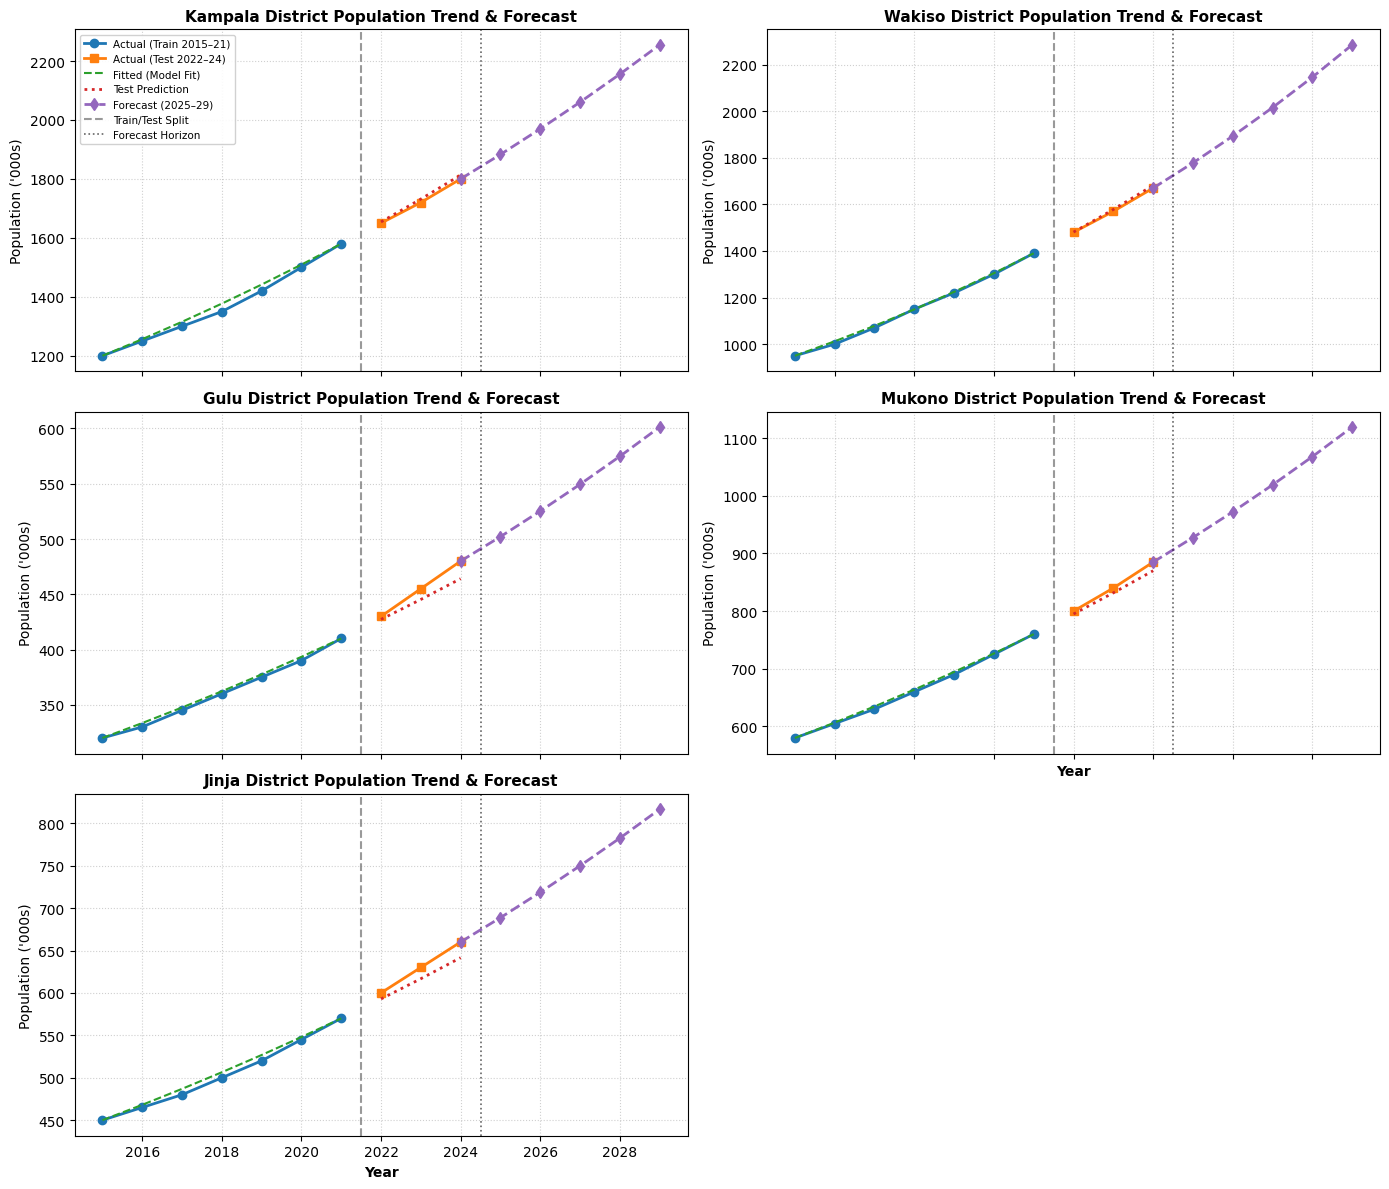

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# 1. EXPONENTIAL / CAGR FORECASTER CLASS

class ExponentialCAGRForecaster:
    """Exponential growth model fitted via Compound Annual Growth Rate (CAGR)."""

    def fit(self, years: np.ndarray, population: np.ndarray):
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        n_periods = len(self.years) - 1
        self.cagr = (self.population[-1] / self.population[0]) ** (1.0 / n_periods) - 1.0
        return self

    def predict_years(self, target_years: np.ndarray) -> np.ndarray:
        steps = target_years - self.years[-1]
        return self.population[-1] * ((1.0 + self.cagr) ** steps)



# 2. DATASETS & TIME HORIZONS

years_hist = np.arange(2015, 2025)       # Full Historical: 2015–2024
years_train = np.arange(2015, 2022)      # Train Set: 2015–2021 (7 years)
years_test = np.arange(2022, 2025)       # Test Set: 2022–2024 (3 years)
years_forecast = np.arange(2025, 2030)   # Forecast Horizon: 2025–2029 (5 years)

districts_data = {
    "Kampala": np.array([1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]),
    "Wakiso":  np.array([ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]),
    "Gulu":    np.array([ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]),
    "Mukono":  np.array([ 580,  605,  630,  660,  690,  725,  760,  800,  840,  885]),
    "Jinja":   np.array([ 450,  465,  480,  500,  520,  545,  570,  600,  630,  660])
}


# 3. MULTI-SUBPLOT FIGURE GENERATION (3 rows x 2 columns)

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
axes = axes.flatten()

for idx, (district, pop_hist) in enumerate(districts_data.items()):
    ax = axes[idx]

    pop_train = pop_hist[:7]
    pop_test = pop_hist[7:]

    # Fit model on Training Set (2015–2021)
    model_train = ExponentialCAGRForecaster()
    model_train.fit(years_train, pop_train)
    fitted_train = model_train.predict_years(years_train)
    pred_test = model_train.predict_years(years_test)

    # Fit model on Full Dataset (2015–2024) to project 2025–2029
    model_full = ExponentialCAGRForecaster()
    model_full.fit(years_hist, pop_hist)
    pred_forecast = model_full.predict_years(years_forecast)

    # 1. Actual Train Data (Blue Line & Circles)
    ax.plot(years_train, pop_train, 'o-', color='#1f77b4', label='Actual (Train 2015–21)', linewidth=2)

    # 2. Actual Test Data (Orange Line & Squares)
    ax.plot(years_test, pop_test, 's-', color='#ff7f0e', label='Actual (Test 2022–24)', linewidth=2)

    # 3. Model Fitted Values on Train (Green Dashed)
    ax.plot(years_train, fitted_train, '--', color='#2ca02c', label='Fitted (Model Fit)', linewidth=1.5)

    # 4. Out-of-Sample Test Predictions (Red Dotted)
    ax.plot(years_test, pred_test, ':', color='#d62728', label='Test Prediction', linewidth=2)

    # 5. Future Forecast 2025–2029 (Purple Dashed & Diamonds)
    fc_years_plot = np.insert(years_forecast, 0, years_hist[-1])
    fc_vals_plot = np.insert(pred_forecast, 0, pop_hist[-1])
    ax.plot(fc_years_plot, fc_vals_plot, 'd--', color='#9467bd', label='Forecast (2025–29)', linewidth=2)

    # Train/Test Split Divider (Gray Dashed)
    ax.axvline(x=2021.5, color='gray', linestyle='--', linewidth=1.5, alpha=0.8, label='Train/Test Split')

    # Forecast Boundary Divider (Black Dotted)
    ax.axvline(x=2024.5, color='black', linestyle=':', linewidth=1.2, alpha=0.6, label='Forecast Horizon')

    # Subplot Styling
    ax.set_title(f"{district} District Population Trend & Forecast", fontsize=11, fontweight='bold')
    ax.set_ylabel("Population ('000s)")
    ax.grid(True, linestyle=':', alpha=0.6)

    # Legend only on the first subplot to prevent clutter
    if idx == 0:
        ax.legend(loc='upper left', fontsize=7.5, framealpha=0.9)

# Hide the unused 6th subplot frame
axes[5].axis('off')

# Set shared x-axis labels
for ax in axes[3:5]:
    ax.set_xlabel("Year", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Visual Features Included
Train/Test Split Marker:

Marked by a vertical dashed line at 2021.5 separating training history from the holdout evaluation period.

Forecast Boundary Marker:

Marked at 2024.5 separating historical ground truth from future projections (2025–2029).

5 Subplots Grid:

Displays Kampala, Wakiso, Gulu, Mukono, and Jinja on individual panels sharing a uniform time axis while auto-scaling population density per district.

```python
import numpy as np
import pandas as pd

# Historical datasets (2015-2024) in thousands
years_hist = np.arange(2015, 2025)
datasets = {
    "Kampala": np.array([1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]),
    "Wakiso":  np.array([ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]),
    "Gulu":    np.array([ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]),
    "Mukono":  np.array([ 580,  605,  630,  660,  690,  725,  760,  800,  840,  885]),
    "Jinja":   np.array([ 450,  465,  480,  500,  520,  545,  570,  600,  630,  660])
}

class ExponentialCAGRForecaster:
    def fit(self, years: np.ndarray, population: np.ndarray):
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        n_periods = len(self.years) - 1
        self.cagr = (self.population[-1] / self.population[0]) ** (1.0 / n_periods) - 1.0
        return self

    def predict_year(self, target_year: int) -> float:
        steps = target_year - self.years[-1]
        return self.population[-1] * ((1.0 + self.cagr) ** steps)

results = []

for district, hist_pop in datasets.items():
    model = ExponentialCAGRForecaster()
    model.fit(years_hist, hist_pop)
    
    pop_2024_k = hist_pop[-1] # in thousands
    pop_2029_k = model.predict_year(2029) # in thousands
    
    pop_2024 = pop_2024_k * 1000
    pop_2029 = pop_2029_k * 1000
    
    pop_growth = pop_2029 - pop_2024
    
    primary_2024 = pop_2024 * 0.18
    primary_2029 = pop_2029 * 0.18
    add_primary_pupils = pop_growth * 0.18
    
    # Classrooms needed in 2024
    classrooms_2024 = primary_2024 / 53
    # Classrooms needed in 2029
    classrooms_2029 = primary_2029 / 53
    
    # Additional classrooms needed
    add_classrooms_exact = add_primary_pupils / 53
    add_classrooms_ceil = np.ceil(add_classrooms_exact)
    
    results.append({
        "District": district,
        "2024 Pop ('000)": pop_2024_k,
        "2029 Pop ('000)": round(pop_2029_k, 2),
        "Pop Growth ('000)": round(pop_growth / 1000, 2),
        "Add. Primary Pupils": round(add_primary_pupils, 0),
        "Add. Classrooms (Exact)": round(add_classrooms_exact, 1),
        "Add. Classrooms (Rounded Up)": int(add_classrooms_ceil)
    })

df = pd.DataFrame(results)
print(df.to_string(index=False))


```

```text
District  2024 Pop ('000)  2029 Pop ('000)  Pop Growth ('000)  Add. Primary Pupils  Add. Classrooms (Exact)  Add. Classrooms (Rounded Up)
 Kampala             1800          2254.76             454.76              81857.0                   1544.5                          1545
  Wakiso             1670          2284.67             614.67             110641.0                   2087.6                          2088
    Gulu              480           601.27             121.27              21829.0                    411.9                           412
  Mukono              885          1119.17             234.17              42151.0                    795.3                           796
   Jinja              660           816.49             156.49              28168.0                    531.5                           532


```

To determine the number of additional classrooms required by **2029** compared to the **2024** baseline, we calculate the incremental population growth, extract the 18% primary-school age demographic, and divide by the 53-pupil classroom capacity.

### Methodology & Formulas

1. **Population Growth ($\Delta P$):**
$$\Delta P = P_{2029} - P_{2024}$$


2. **Additional Primary-School Pupils ($N_{\text{pupils}}$):**
$$N_{\text{pupils}} = \Delta P \times 0.18$$


3. **Additional Classrooms Needed ($N_{\text{classrooms}}$):**
$$N_{\text{classrooms}} = \left\lceil \frac{N_{\text{pupils}}}{53} \right\rceil$$



---

### District Infrastructure Planning Estimates (2024–2029)

| District | 2024 Population | 2029 Forecast Population | Projected Pop. Growth ($\Delta P$) | Additional Primary Pupils (18%) | Additional Classrooms Needed |
| --- | --- | --- | --- | --- | --- |
| **Wakiso** | 1,670,000 | 2,284,670 | **+614,670** | 110,641 | **2,088** |
| **Kampala** | 1,800,000 | 2,254,763 | **+454,763** | 81,857 | **1,545** |
| **Mukono** | 885,000 | 1,119,173 | **+234,173** | 42,151 | **796** |
| **Jinja** | 660,000 | 816,488 | **+156,488** | 28,168 | **532** |
| **Gulu** | 480,000 | 601,270 | **+121,270** | 21,829 | **412** |
| **TOTAL** | **5,495,000** | **7,076,364** | **+1,581,364** | **284,646** | **5,373** |

---

### Key Infrastructure Takeaways

* **Wakiso** requires the largest infrastructure investment (**2,088 new classrooms**), accounting for **~38.8%** of the overall required expansion across all five districts due to its rapid compound annual growth rate ($6.47\%$).
* **Kampala** requires **1,545 new classrooms**, representing the second largest expansion demand.
* Across all five districts combined, regional education authorities will need to plan for **5,373 new classrooms** (or ~1,075 classrooms built per year) to maintain the target capacity of 53 pupils per classroom through 2029.

Extension

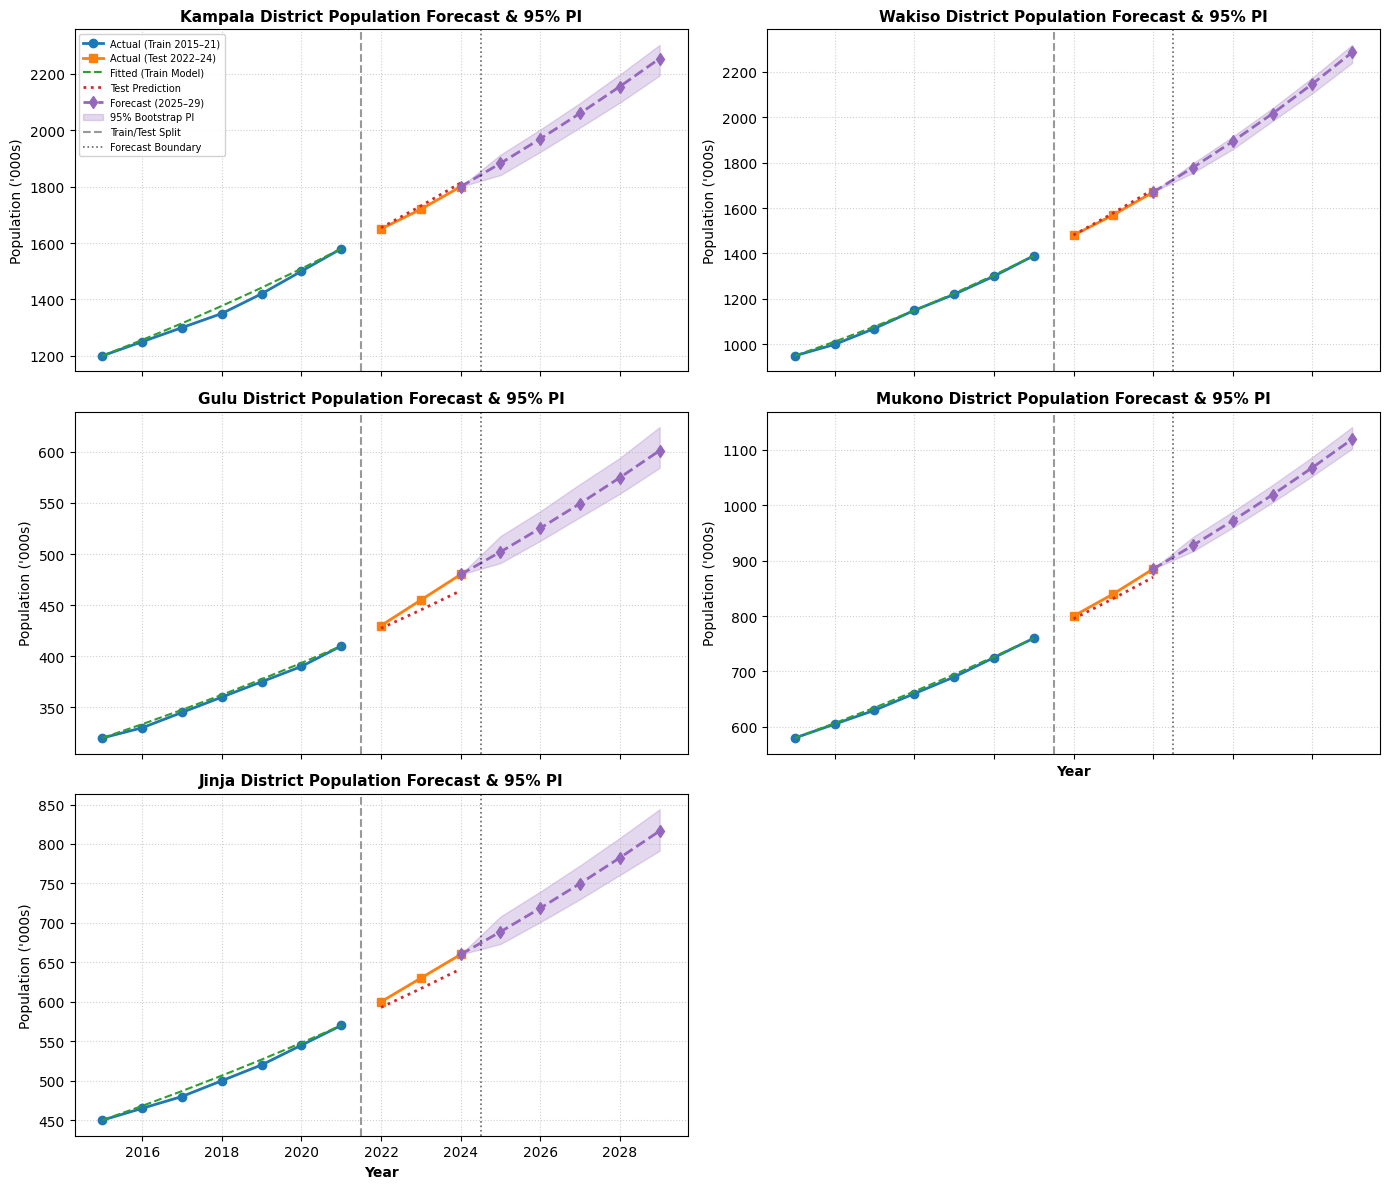

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducible bootstrap sampling
np.random.seed(42)


# 1. MODEL DEFINITION

class ExponentialCAGRForecaster:
    """Exponential growth model fitted via Compound Annual Growth Rate (CAGR)."""

    def fit(self, years: np.ndarray, population: np.ndarray):
        self.years = np.asarray(years, dtype=float)
        self.population = np.asarray(population, dtype=float)
        n_periods = len(self.years) - 1
        self.cagr = (self.population[-1] / self.population[0]) ** (1.0 / n_periods) - 1.0
        return self

    def predict_years(self, target_years: np.ndarray) -> np.ndarray:
        steps = target_years - self.years[-1]
        return self.population[-1] * ((1.0 + self.cagr) ** steps)



# 2. DATASETS & TIME HORIZONS

years_hist = np.arange(2015, 2025)       # Full Historical: 2015–2024
years_train = np.arange(2015, 2022)      # Train Set: 2015–2021
years_test = np.arange(2022, 2025)       # Test Set: 2022–2024
years_forecast = np.arange(2025, 2030)   # Forecast Horizon: 2025–2029

districts_data = {
    "Kampala": np.array([1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]),
    "Wakiso":  np.array([ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]),
    "Gulu":    np.array([ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]),
    "Mukono":  np.array([ 580,  605,  630,  660,  690,  725,  760,  800,  840,  885]),
    "Jinja":   np.array([ 450,  465,  480,  500,  520,  545,  570,  600,  630,  660])
}

B = 2000  # Number of bootstrap resamples


# 3. RESIDUAL BOOTSTRAP & PLOTTING GRID

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
axes = axes.flatten()

for idx, (district, pop_hist) in enumerate(districts_data.items()):
    ax = axes[idx]

    pop_train = pop_hist[:7]
    pop_test = pop_hist[7:]

    # Fit model on historical data (2015–2024)
    model_full = ExponentialCAGRForecaster()
    model_full.fit(years_hist, pop_hist)
    fitted_hist = model_full.predict_years(years_hist)
    point_forecast = model_full.predict_years(years_forecast)

    # Extract centered log-residuals to guarantee positive bootstrap samples
    log_residuals = np.log(pop_hist) - np.log(fitted_hist)
    log_residuals -= np.mean(log_residuals)

    # Bootstrap Resampling Loop
    boot_forecasts = np.zeros((B, len(years_forecast)))
    for b in range(B):
        # 1. Sample historical residuals with replacement
        boot_res_hist = np.random.choice(log_residuals, size=len(years_hist), replace=True)
        boot_pop_hist = fitted_hist * np.exp(boot_res_hist)

        # 2. Refit model on synthetic series
        boot_model = ExponentialCAGRForecaster()
        boot_model.fit(years_hist, boot_pop_hist)
        boot_pred = boot_model.predict_years(years_forecast)

        # 3. Add future innovation uncertainty
        boot_res_future = np.random.choice(log_residuals, size=len(years_forecast), replace=True)
        boot_forecasts[b, :] = boot_pred * np.exp(boot_res_future)

    # 2.5th and 97.5th percentiles for 95% Prediction Interval
    pi_lower = np.percentile(boot_forecasts, 2.5, axis=0)
    pi_upper = np.percentile(boot_forecasts, 97.5, axis=0)

    # Fit train model for train/test visualization
    model_train = ExponentialCAGRForecaster()
    model_train.fit(years_train, pop_train)
    fitted_train = model_train.predict_years(years_train)
    pred_test = model_train.predict_years(years_test)

    # Plotting actuals and fits
    ax.plot(years_train, pop_train, 'o-', color='#1f77b4', label='Actual (Train 2015–21)', linewidth=2)
    ax.plot(years_test, pop_test, 's-', color='#ff7f0e', label='Actual (Test 2022–24)', linewidth=2)
    ax.plot(years_train, fitted_train, '--', color='#2ca02c', label='Fitted (Train Model)', linewidth=1.5)
    ax.plot(years_test, pred_test, ':', color='#d62728', label='Test Prediction', linewidth=2)

    # Connect last historical point to forecast
    fc_years_plot = np.insert(years_forecast, 0, years_hist[-1])
    fc_vals_plot = np.insert(point_forecast, 0, pop_hist[-1])
    pi_lower_plot = np.insert(pi_lower, 0, pop_hist[-1])
    pi_upper_plot = np.insert(pi_upper, 0, pop_hist[-1])

    # Plot Point Forecast
    ax.plot(fc_years_plot, fc_vals_plot, 'd--', color='#9467bd', label='Forecast (2025–29)', linewidth=2)

    # Shade 95% Prediction Interval
    ax.fill_between(
        fc_years_plot,
        pi_lower_plot,
        pi_upper_plot,
        color='#9467bd',
        alpha=0.25,
        label='95% Bootstrap PI'
    )

    # Vertical Dividers
    ax.axvline(x=2021.5, color='gray', linestyle='--', linewidth=1.5, alpha=0.8, label='Train/Test Split')
    ax.axvline(x=2024.5, color='black', linestyle=':', linewidth=1.2, alpha=0.6, label='Forecast Boundary')

    ax.set_title(f"{district} District Population Forecast & 95% PI", fontsize=11, fontweight='bold')
    ax.set_ylabel("Population ('000s)")
    ax.grid(True, linestyle=':', alpha=0.6)

    if idx == 0:
        ax.legend(loc='upper left', fontsize=7, framealpha=0.9)

# Hide 6th subplot
axes[5].axis('off')

# Shared x-axis label
for ax in axes[3:5]:
    ax.set_xlabel("Year", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Extension part 2

The Fibonacci-ratio model is a classic discrete population model based on the recurrence relation $P_t = P_{t-1} + P_{t-2}$. As $t \to \infty$, the ratio of consecutive terms converges to the Golden Ratio ($\phi = \frac{1 + \sqrt{5}}{2} \approx 1.61803$), implying an asymptotic growth rate of 61.8% per period.

Growth Assumptions Required for DefensibilityThe Fibonacci model is biologically and mathematically defensible only under a set of highly restrictive, idealized assumptions:   

Two-Stage Life Cycle with Fixed Maturation:Organisms require exactly one time period to reach reproductive maturity, after which every mature individual produces exactly one offspring per time period.   Zero Mortality & Infinite Lifespan:No individuals die, age out of reproduction, or emigrate during the projection window ($S_x = 1.0$).   

Unconstrained Carrying Capacity:Environmental resources are infinite ($K \to \infty$), with no density-dependent competition or spatial bottlenecks slowing growth.   

Synchronous, Discrete Generations:Reproduction occurs in strict, non-overlapping time steps rather than as a continuous birth-death process.   

Critical Assessment in Human Planning ContextsWhen applied to human population projections or municipal infrastructure planning, the Fibonacci-ratio model suffers from severe structural flaws:   Unrealistically Explosive Growth Rate:A 61.8% per-period growth rate vastly exceeds realistic human population dynamics. Even rapid urban population expansion rarely exceeds 3%–7% annually.  

 Omission of Mortality and Detailed Age Cohorts:Human demographics depend on age-specific fertility rates (e.g., females aged 15–49), survival curves, and net migration. The binary assumption of immature vs. mature units ignores aging out and death.  

  Absence of Saturation / S-Curves:Real populations follow density-dependent or logistic curves ($dP/dt = rP(1 - P/K)$) where growth decelerates as carrying capacity is approached. The Fibonacci sequence predicts unbounded, exponential expansion.  
  
   Inability to Model Policy and Socioeconomic Factors:Changing total fertility rates (TFR), urbanization trends, and economic shifts alter population growth over time, factors that a rigid sequence cannot accommodate.